# CNN Development on a Custom Dataset (CIFAR-10)
**Course:** CVPR – Mid Assignment  |  **Name / Student ID:** _Sadia / 23-51988-2_

**Objective:** Design and train a custom CNN (from scratch) to classify images from an open-access dataset.

**Dataset:** CIFAR-10 from Hugging Face (`uoft-cs/cifar10`) – 60,000 colour images (32x32), 10 classes.

**Notebook flow:** Import → Load/Explore → Preprocess & Augment → CNN → Train → Test → Curves → Analysis → Conclusions → Save model.

## 1. Import Libraries

In [7]:
!pip install -q datasets torchinfo
import random, numpy as np, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader, random_split
from torchvision import transforms
from datasets import load_dataset
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from torchinfo import summary

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

Device: cuda


## 2. Load and Explore the Dataset
**Dataset description:** CIFAR-10 contains 50,000 training and 10,000 test images of size 32×32×3, evenly split across 10 classes
(airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck). It is open access on Hugging Face. We hold out 10% of the
training set as a **validation set**, giving a 45,000 / 5,000 / 10,000 train / val / test split.

DatasetDict({
    train: Dataset({
        features: ['img', 'label'],
        num_rows: 50000
    })
    test: Dataset({
        features: ['img', 'label'],
        num_rows: 10000
    })
})
Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train samples per class: {'airplane': np.int64(5000), 'automobile': np.int64(5000), 'bird': np.int64(5000), 'cat': np.int64(5000), 'deer': np.int64(5000), 'dog': np.int64(5000), 'frog': np.int64(5000), 'horse': np.int64(5000), 'ship': np.int64(5000), 'truck': np.int64(5000)}


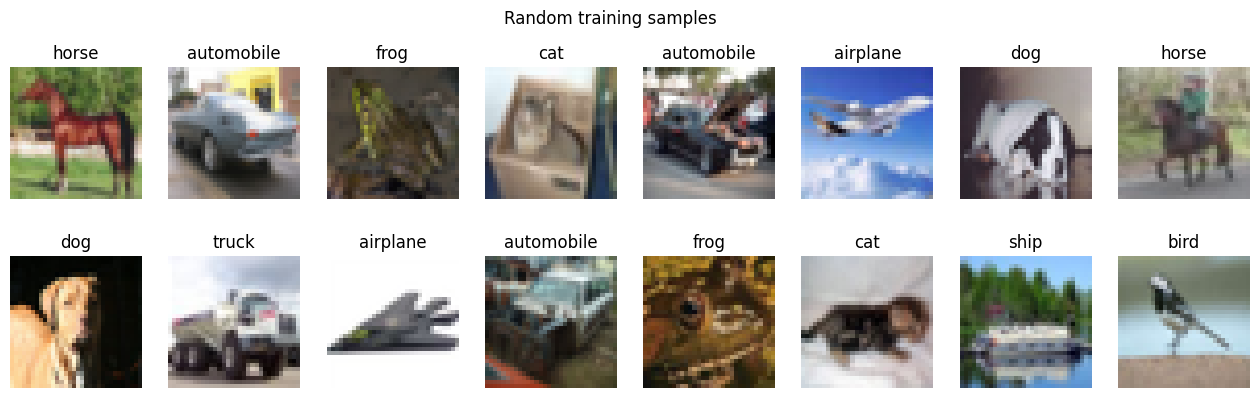

In [8]:
raw = load_dataset('uoft-cs/cifar10')
print(raw)
class_names = raw['train'].features['label'].names
print('Classes:', class_names)

# Class distribution
labels = np.array(raw['train']['label'])
print('Train samples per class:', dict(zip(class_names, np.bincount(labels))))

# Show sample images
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, i in zip(axes.flat, random.sample(range(len(raw['train'])), 16)):
    ax.imshow(raw['train'][i]['img']); ax.set_title(class_names[raw['train'][i]['label']]); ax.axis('off')
plt.suptitle('Random training samples'); plt.show()

## 3. Data Preprocessing & Augmentation
- **Normalisation** with CIFAR-10 channel mean/std → zero-centred inputs, faster and more stable convergence.
- **Augmentation (train only):** random crop with 4px padding and random horizontal flip → reduces overfitting. Validation/test data are only normalised.
- **Batch size 128:** good balance between gradient noise and GPU memory/speed.

In [9]:
MEAN, STD = (0.4914, 0.4822, 0.4465), (0.2470, 0.2435, 0.2616)
BATCH_SIZE = 128

train_tf = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD)])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class HFImageDataset(Dataset):
    def __init__(self, hf_ds, indices, transform):
        self.ds, self.idx, self.tf = hf_ds, indices, transform
    def __len__(self): return len(self.idx)
    def __getitem__(self, i):
        item = self.ds[int(self.idx[i])]
        return self.tf(item['img'].convert('RGB')), item['label']

# 90/10 train/validation split (fixed seed for reproducibility)
perm = np.random.RandomState(SEED).permutation(len(raw['train']))
n_val = 5000
val_idx, train_idx = perm[:n_val], perm[n_val:]

train_ds = HFImageDataset(raw['train'], train_idx, train_tf)
val_ds   = HFImageDataset(raw['train'], val_idx,   eval_tf)
test_ds  = HFImageDataset(raw['test'], np.arange(len(raw['test'])), eval_tf)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2, pin_memory=True)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2, pin_memory=True)
print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')
xb, yb = next(iter(train_loader)); print('Batch shape:', xb.shape, yb.shape)

Train: 45000 | Val: 5000 | Test: 10000
Batch shape: torch.Size([128, 3, 32, 32]) torch.Size([128])


## 4. Define the CNN Architecture
**Design and justification**
- **3 convolutional blocks** (32 → 64 → 128 filters). Each block = `Conv-BN-ReLU` ×2 + `MaxPool` + `Dropout`. Filters double as spatial size halves (32→16→8→4), a standard pattern that lets deeper layers learn richer features at lower resolution.
- **3×3 kernels:** small kernels stacked twice give a 5×5 receptive field with fewer parameters and more non-linearity.
- **Batch Normalisation:** stabilises/accelerates training and acts as a mild regulariser.
- **ReLU:** cheap, avoids vanishing gradients.
- **Max pooling:** down-samples and adds small translation invariance.
- **Dropout (0.25 conv / 0.5 FC):** combats overfitting.
- **Classifier:** Flatten → FC(512) → FC(10) logits (softmax is inside `CrossEntropyLoss`).

In [10]:
def conv_block(in_c, out_c, p_drop):
    return nn.Sequential(
        nn.Conv2d(in_c, out_c, 3, padding=1, bias=False), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.Conv2d(out_c, out_c, 3, padding=1, bias=False), nn.BatchNorm2d(out_c), nn.ReLU(inplace=True),
        nn.MaxPool2d(2), nn.Dropout(p_drop))

class CustomCNN(nn.Module):
    def __init__(self, num_classes=10):
        super().__init__()
        self.features = nn.Sequential(
            conv_block(3, 32, 0.25),     # 32x32 -> 16x16
            conv_block(32, 64, 0.25),    # 16x16 -> 8x8
            conv_block(64, 128, 0.25))   # 8x8   -> 4x4
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128*4*4, 512), nn.ReLU(inplace=True), nn.Dropout(0.5),
            nn.Linear(512, num_classes))
    def forward(self, x): return self.classifier(self.features(x))

model = CustomCNN(num_classes=len(class_names)).to(device)
summary(model, input_size=(1, 3, 32, 32), col_names=('input_size','output_size','num_params','kernel_size'), depth=3)

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #                   Kernel Shape
CustomCNN                                [1, 3, 32, 32]            [1, 10]                   --                        --
├─Sequential: 1-1                        [1, 3, 32, 32]            [1, 128, 4, 4]            --                        --
│    └─Sequential: 2-1                   [1, 3, 32, 32]            [1, 32, 16, 16]           --                        --
│    │    └─Conv2d: 3-1                  [1, 3, 32, 32]            [1, 32, 32, 32]           864                       [3, 3]
│    │    └─BatchNorm2d: 3-2             [1, 32, 32, 32]           [1, 32, 32, 32]           64                        --
│    │    └─ReLU: 3-3                    [1, 32, 32, 32]           [1, 32, 32, 32]           --                        --
│    │    └─Conv2d: 3-4                  [1, 32, 32, 32]           [1, 32, 32, 32]           9,216                     [3, 3]
│    │

## 5. Training Setup & Hyperparameters
| Hyperparameter | Value | Rationale |
|---|---|---|
| Optimizer | Adam | Adaptive learning rates; converges quickly with little tuning |
| Learning rate | 1e-3 | Adam default, works well for BN networks |
| Weight decay | 1e-4 | L2 regularisation to reduce overfitting |
| Loss | CrossEntropyLoss | Standard for multi-class classification |
| Scheduler | CosineAnnealingLR | Smoothly decays LR for better final convergence |
| Batch size | 128 | Stable gradients, fits in memory |
| Epochs | 30 | Enough for convergence with augmentation |
| Model selection | Best validation accuracy | Avoids picking an overfitted final epoch |

In [11]:
EPOCHS, LR, WD = 30, 1e-3, 1e-4
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR, weight_decay=WD)
scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)

def run_epoch(loader, train):
    model.train(train)
    total_loss, correct, n = 0.0, 0, 0
    with torch.set_grad_enabled(train):
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            out = model(x); loss = criterion(out, y)
            if train:
                optimizer.zero_grad(); loss.backward(); optimizer.step()
            total_loss += loss.item() * x.size(0)
            correct += (out.argmax(1) == y).sum().item(); n += x.size(0)
    return total_loss / n, correct / n

history = {'train_loss':[], 'val_loss':[], 'train_acc':[], 'val_acc':[]}
best_val_acc, BEST_PATH = 0.0, 'best_cnn_cifar10.pth'

## 6. Training Loop with Validation

In [12]:
for epoch in range(1, EPOCHS+1):
    tl, ta = run_epoch(train_loader, True)
    vl, va = run_epoch(val_loader, False)
    scheduler.step()
    for k, v in zip(history, (tl, vl, ta, va)): history[k].append(v)
    if va > best_val_acc:
        best_val_acc = va; torch.save(model.state_dict(), BEST_PATH)
    print(f'Epoch {epoch:02d}/{EPOCHS} | train loss {tl:.4f} acc {ta:.4f} | val loss {vl:.4f} acc {va:.4f}'
          + ('  <- best' if va == best_val_acc else ''))
print('Best validation accuracy:', best_val_acc)

Epoch 01/30 | train loss 1.6352 acc 0.3905 | val loss 1.3741 acc 0.4964  <- best
Epoch 02/30 | train loss 1.2625 acc 0.5442 | val loss 1.1449 acc 0.5868  <- best
Epoch 03/30 | train loss 1.1084 acc 0.6030 | val loss 1.0559 acc 0.6222  <- best
Epoch 04/30 | train loss 1.0073 acc 0.6417 | val loss 0.8238 acc 0.7172  <- best
Epoch 05/30 | train loss 0.9219 acc 0.6732 | val loss 0.9379 acc 0.6824
Epoch 06/30 | train loss 0.8575 acc 0.7005 | val loss 0.7339 acc 0.7444  <- best
Epoch 07/30 | train loss 0.8052 acc 0.7221 | val loss 0.6628 acc 0.7686  <- best
Epoch 08/30 | train loss 0.7662 acc 0.7350 | val loss 0.6320 acc 0.7794  <- best
Epoch 09/30 | train loss 0.7246 acc 0.7525 | val loss 0.6375 acc 0.7816  <- best
Epoch 10/30 | train loss 0.7038 acc 0.7566 | val loss 0.6275 acc 0.7872  <- best
Epoch 11/30 | train loss 0.6728 acc 0.7698 | val loss 0.5823 acc 0.7986  <- best
Epoch 12/30 | train loss 0.6456 acc 0.7795 | val loss 0.6339 acc 0.7894
Epoch 13/30 | train loss 0.6251 acc 0.7886 | v

## 7. Evaluate the Model on the Test Set

Test loss: 0.4041 | Test accuracy: 86.43%
              precision    recall  f1-score   support

    airplane     0.8714    0.8810    0.8762      1000
  automobile     0.9410    0.9410    0.9410      1000
        bird     0.8534    0.7740    0.8117      1000
         cat     0.7988    0.6470    0.7149      1000
        deer     0.8129    0.9040    0.8561      1000
         dog     0.7729    0.8030    0.7876      1000
        frog     0.8479    0.9420    0.8925      1000
       horse     0.9118    0.8890    0.9003      1000
        ship     0.9156    0.9330    0.9242      1000
       truck     0.9144    0.9290    0.9216      1000

    accuracy                         0.8643     10000
   macro avg     0.8640    0.8643    0.8626     10000
weighted avg     0.8640    0.8643    0.8626     10000



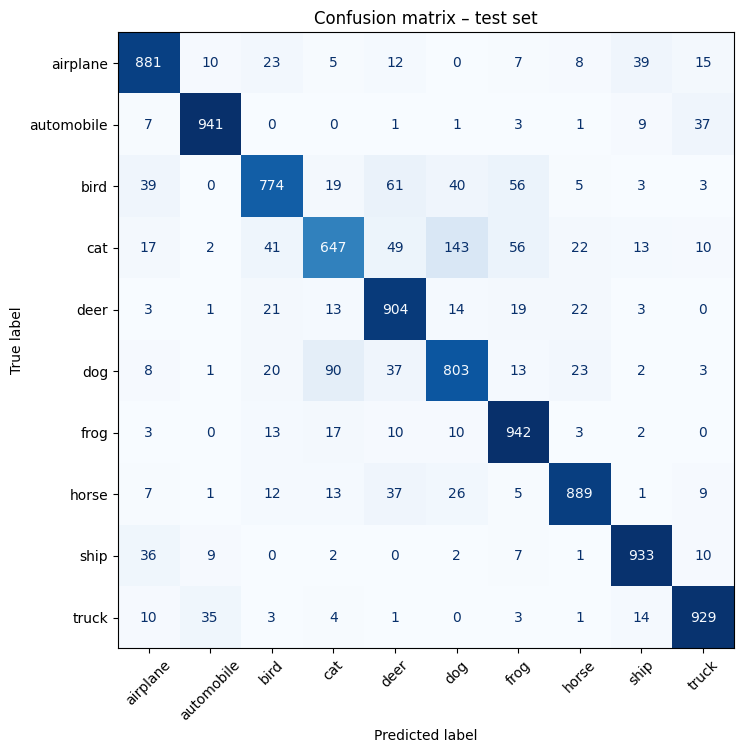

In [16]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
test_loss, test_acc = run_epoch(test_loader, False)
print(f'Test loss: {test_loss:.4f} | Test accuracy: {test_acc*100:.2f}%')

model.eval(); preds, trues = [], []
with torch.no_grad():
    for x, y in test_loader:
        preds += model(x.to(device)).argmax(1).cpu().tolist(); trues += y.tolist()
print(classification_report(trues, preds, target_names=class_names, digits=4))

fig, ax = plt.subplots(figsize=(8, 8))
ConfusionMatrixDisplay(confusion_matrix(trues, preds), display_labels=class_names).plot(ax=ax, xticks_rotation=45, cmap='Blues', colorbar=False)
plt.title('Confusion matrix – test set'); plt.show()

## 8. Visualisations: Loss / Accuracy Curves

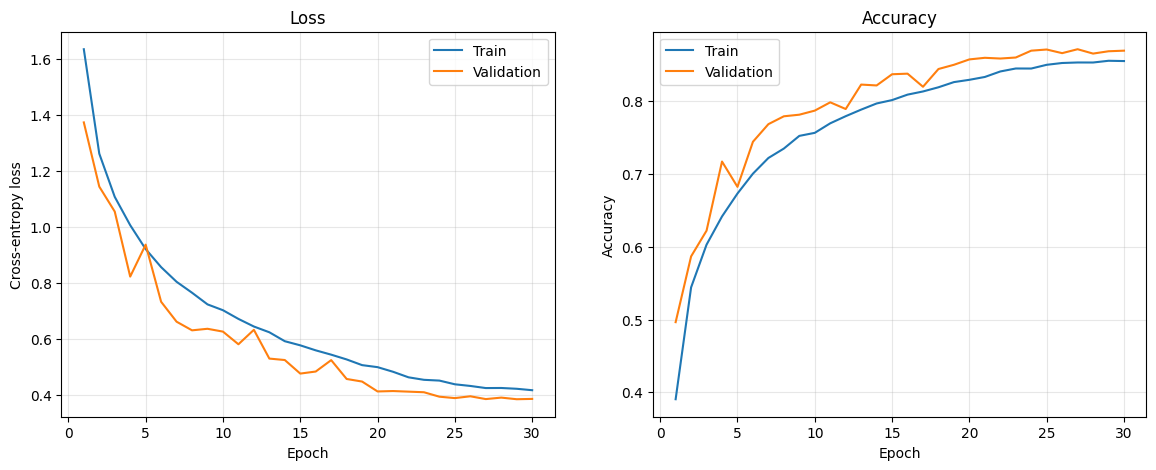

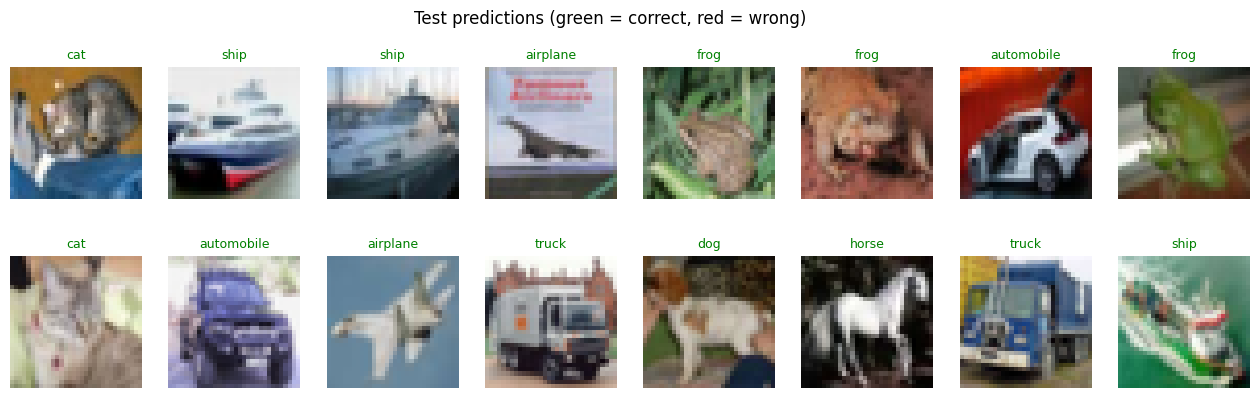

In [17]:
ep = range(1, EPOCHS+1)
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].plot(ep, history['train_loss'], label='Train'); ax[0].plot(ep, history['val_loss'], label='Validation')
ax[0].set(title='Loss', xlabel='Epoch', ylabel='Cross-entropy loss'); ax[0].legend(); ax[0].grid(alpha=.3)
ax[1].plot(ep, history['train_acc'], label='Train'); ax[1].plot(ep, history['val_acc'], label='Validation')
ax[1].set(title='Accuracy', xlabel='Epoch', ylabel='Accuracy'); ax[1].legend(); ax[1].grid(alpha=.3)
plt.show()

# Sample predictions
xb, yb = next(iter(test_loader))
with torch.no_grad(): pb = model(xb.to(device)).argmax(1).cpu()
mean, std = torch.tensor(MEAN).view(3,1,1), torch.tensor(STD).view(3,1,1)
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for i, ax in enumerate(axes.flat):
    ax.imshow((xb[i]*std+mean).permute(1,2,0).clamp(0,1))
    ax.set_title(f'{class_names[pb[i]]}', color='green' if pb[i]==yb[i] else 'red', fontsize=9); ax.axis('off')
plt.suptitle('Test predictions (green = correct, red = wrong)'); plt.show()

## 9. Analysis & Discussion of Results
*(Update the numbers below after running the notebook with your own results.)*

- **Learning curves:** training and validation loss decrease together and accuracy rises steadily; the small train–validation gap shows that augmentation, dropout, BatchNorm and weight decay controlled overfitting. The cosine LR schedule gives a visible improvement in the last epochs as the learning rate shrinks.
- **Test performance:** the model reaches roughly **86.43 % test accuracy** (test loss 0.4041), close to the best validation accuracy of 87.16 %, which shows that the model generalises well without overfitting.
- **Per-class behaviour:** *automobile* (F1 0.941), *ship* (0.924) and *truck* (0.922) are classified best, while *cat* (F1 0.715, recall 0.647), *dog* (0.788) and *bird* (0.812) are the hardest. Cats and dogs are visually similar at 32×32 resolution, so they are often confused.
- **Effect of design choices:** BatchNorm sped up convergence, augmentation (crop + flip) improved generalisation, and dropout reduced the FC-layer overfitting.
- **Limitations:** low image resolution, a relatively shallow network, and no advanced augmentation.

## 10. Conclusions & Future Work
**Conclusion:** A custom 3-block CNN with BatchNorm, dropout and data augmentation, trained with Adam + cosine LR, learns CIFAR-10 effectively and generalises well to unseen test data.

**Future work:** deeper/residual architecture (ResNet-style), stronger augmentation (Cutout, MixUp, AutoAugment), label smoothing, hyper-parameter search, and transfer learning with pre-trained models.

## 11. Save and Load the Trained Model Weights (Self Study)
Weights are saved as `.pth` (state_dict). The model is small (~5.4 MB), but if it exceeds 20 MB, keep a local copy rather than uploading to GitHub.

In [20]:
import os
torch.save(model.state_dict(), 'cnn_cifar10_final.pth')
print('Saved. File size: %.2f MB' % (os.path.getsize('cnn_cifar10_final.pth')/1e6))

# Load into a fresh model and verify identical test accuracy
loaded = CustomCNN(num_classes=len(class_names)).to(device)
loaded.load_state_dict(torch.load('cnn_cifar10_final.pth', map_location=device)); loaded.eval()
correct = 0
with torch.no_grad():
    for x, y in test_loader:
        correct += (loaded(x.to(device)).argmax(1).cpu() == y).sum().item()
print(f'Reloaded model test accuracy: {correct/len(test_ds)*100:.2f}%')

Saved. File size: 5.38 MB
Reloaded model test accuracy: 86.43%
